# K-means

## 군집 대상과 입력

- K-means는 관측(observation)을 가장 가까운 중심(centroid)에 배정하고 중심을 다시 계산하여 $K$개의 군집(cluster)을 찾는 알고리즘이다.
- 입력은 동서 방향으로 넓게 분포한 배달 수령 위치 360개이며 두 좌표의 단위는 km이다. 합성 데이터(synthetic data)를 만들 때의 정답 라벨(label)은 사용하지 않는다.
- $K$는 미리 정하는 군집 수이며 각 군집의 관측 수를 지정하지는 않는다.

## 중심과 군집 내 거리

### 중심의 정의

- 중심(centroid)은 같은 군집에 배정된 관측의 좌표별 평균(mean)이다.

  $\displaystyle \boldsymbol{\mu}_k=\frac{1}{|C_k|}\sum_{i\in C_k}\mathbf{x}_i.$

- $C_k$는 군집 $k$의 관측 번호 집합이고 $|C_k|$는 관측 수이다. $\mathbf{x}_i$는 위치, $\boldsymbol{\mu}_k$는 그 군집의 중심이다.
- 중심은 원래 관측 중 하나일 필요가 없다. 실제 지도에서는 건물 안처럼 접근하기 어려운 곳에 놓일 수도 있다.

### 목적함수

- 목적함수(objective function)는 각 관측과 배정된 중심 사이의 거리 제곱 합이며, K-means는 이 값을 줄인다.

  $\displaystyle J=\sum_{i=1}^{n}\left\|\mathbf{x}_i-\boldsymbol{\mu}_{c_i}\right\|^2.$

- $n$은 전체 관측 수, $c_i$는 관측 $i$의 군집 번호이다. 멀리 떨어진 관측은 제곱 때문에 비용(cost) $J$에 더 크게 기여한다.
- 이 비용은 군집 내 제곱합(within-cluster sum of squares)이며 scikit-learn에서는 inertia라고 부른다. 분류 정확도(accuracy)와는 다르다. 같은 좌표와 단위에서 결과를 비교해야 한다.


## 배정과 중심 갱신

### 가장 가까운 중심에 배정

- 배정(assignment) 단계는 중심을 고정하고 각 관측을 가장 가까운 중심의 군집으로 옮긴다.

  $\displaystyle c_i=\underset{k}{\arg\min}\;\left\|\mathbf{x}_i-\boldsymbol{\mu}_k\right\|^2.$

- $\arg\min$은 거리가 가장 작은 군집 번호를 반환한다. 관측 위치는 움직이지 않고 소속만 바뀐다.

### 배정된 관측의 평균으로 이동

- 갱신(update) 단계는 소속을 고정하고 각 중심을 해당 관측의 평균으로 옮긴다. 두 단계를 반복하면 $J$는 줄거나 그대로 유지된다.

  <img src="assets/02_assignment_and_update.png" alt="실제 K-means 배정 결과와 평균으로 이동하는 중심" width="512" style="max-width:100%;height:auto;">

- 소속이 더 이상 바뀌지 않으면 이 예제의 반복을 마친다. 초기 중심에 따라 다른 결과에 도달할 수 있으므로 수렴(convergence)이 최적의 결과를 보장하지는 않는다.
- 세 집단이 일부 겹치는 위치에 초기 중심을 서쪽으로 모아 둔다. 이 초기화(initialization)에서는 경계 부근의 관측이 여러 번 소속을 바꾸며 중심이 퍼져 나간다. 관측이 없는 군집은 기존 중심을 유지한다.

## 단계와 군집 수의 변화

- 기본값 $K=3$은 배정과 평균 갱신을 14번 반복하며, 두 동작을 나누어 28단계로 표시한다. 중간 위치를 보간(interpolation)하지 않고 실제 계산 결과만 사용한다.
- ‘Step’은 배정 또는 갱신 한 단계를 선택한다. ‘Clusters K’를 바꾸면 새로운 초기 상태에서 시작하고 ‘Fit model’은 현재 $K$의 수렴 결과를 적용한다.
- 점의 위치는 관측값이므로 움직이지 않는다. 배정 단계에서는 소속을 나타내는 색이 바뀌고, 검은 테두리는 직전 배정과 소속이 달라진 관측을 표시한다.
- ×는 현재 중심이고 선은 중심의 이동 경로이다. 갱신 단계의 화살표는 직전 중심에서 실제 평균으로 이동한 방향을 나타낸다.
- 배경색은 마지막 배정 단계에서 각 중심에 가장 가까웠던 영역이다. 중심을 갱신할 때는 배경과 점의 소속을 고정하고, 다음 배정 단계에서 함께 바꾼다.
- 관측과 축 범위는 고정한다. 비용(cost)과 바뀐 소속 수는 선택한 단계의 실제 소속·중심에서 계산한다.


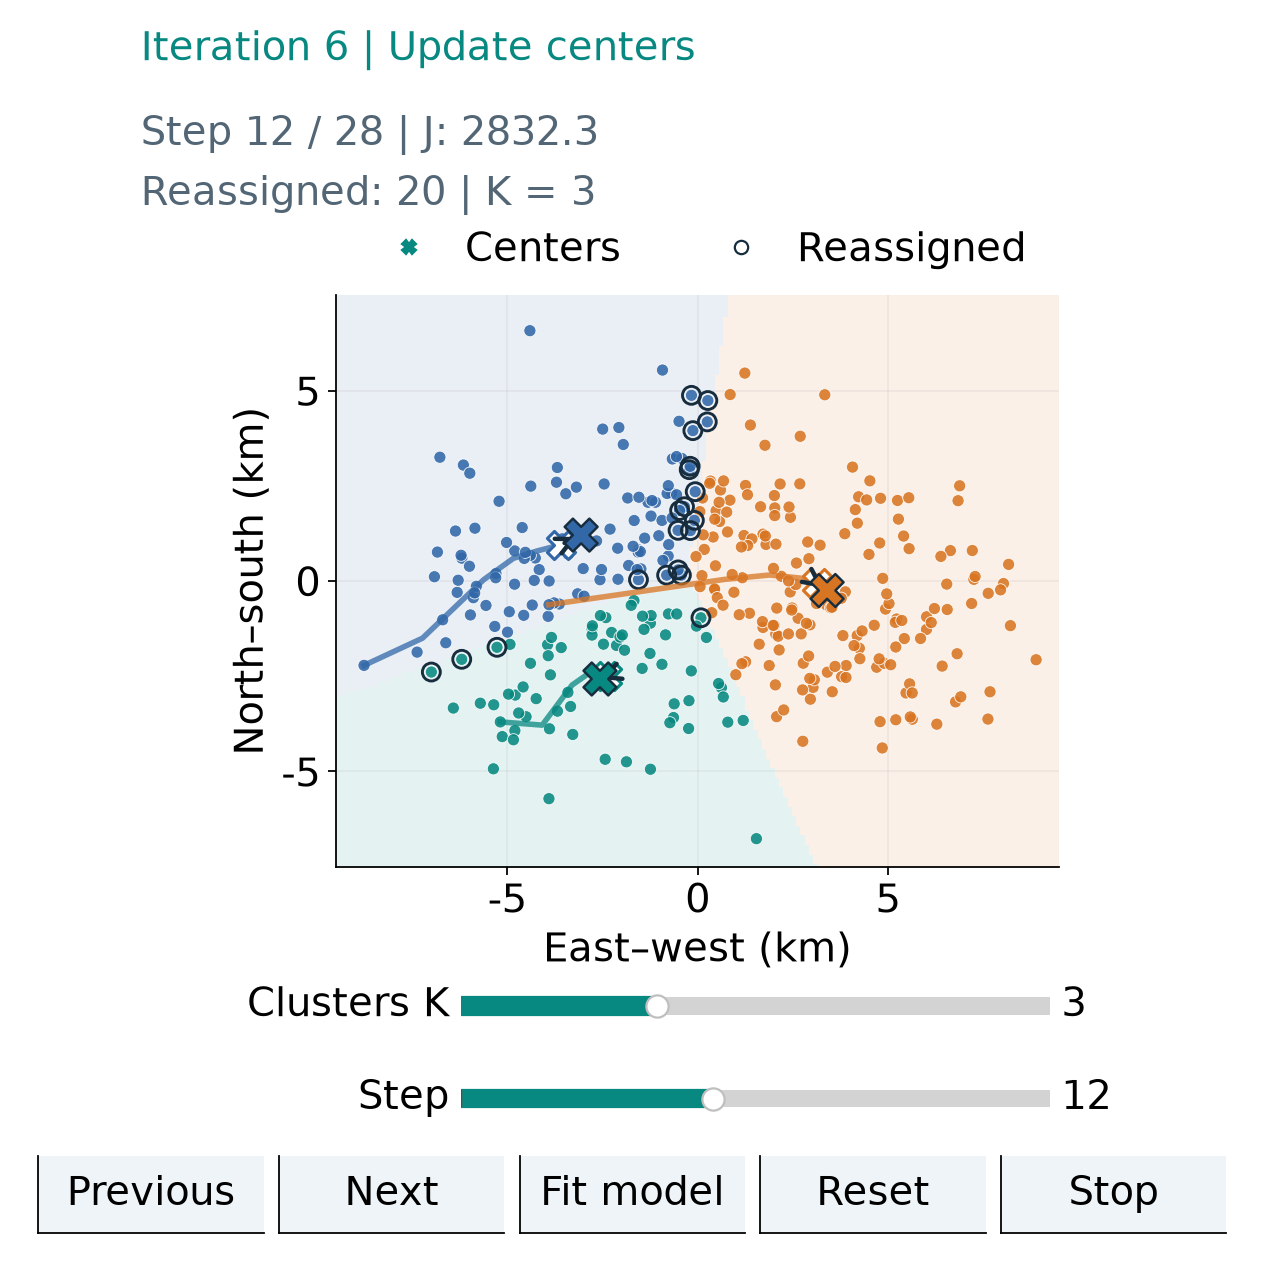

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLUSTERING_STATIC = os.environ.get("CLUSTERING_STATIC") == "1"
CLUSTERING_BROWSER = sys.platform == "emscripten"
if not CLUSTERING_STATIC and not CLUSTERING_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from IPython.display import Image, display

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


for _previous_view in globals().get("_clustering_views", {}).values():
    _previous_view.close()
_clustering_views = {}


class ClusteringExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.85 / height
        self.plot_bottom = bottom
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.connections = [self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())]
        _clustering_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        self.figure.canvas.draw()
        bounds = self.ax.get_tightbbox(self.figure.canvas.get_renderer())
        lower = max(0, bounds.y0 / self.figure.dpi - .04)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            source = self.controls[key]
            if control.value > source.valmax:
                control.value = source.valmax
            control.max = source.valmax
            control.value = source.val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=self.controls[key].val, min=low, max=self.controls[key].valmax, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "130px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLUSTERING_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLUSTERING_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def close(self):
        self.stop()
        for connection in self.connections:
            self.figure.canvas.mpl_disconnect(connection)
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs

COLORS = [BLUE, TEAL, ORANGE, PURPLE, "#a45269"]
locations, _ = make_blobs(
    n_samples=360, centers=[[-4, -1], [0, 1], [4, -1]],
    cluster_std=2.0, random_state=4,
)
bounds = (np.floor(locations[:, 0].min()) - .5, np.ceil(locations[:, 0].max()) + .5,
          np.floor(locations[:, 1].min()) - .5, np.ceil(locations[:, 1].max()) + .5)
grid_x, grid_y = np.meshgrid(np.linspace(*bounds[:2], 170), np.linspace(*bounds[2:], 120))
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

def build_kmeans_states(points, k, max_iter=100):
    order = np.argsort(points[:, 0], kind="stable")
    indices = order[np.linspace(0, int(len(points) * .18), k, dtype=int)]
    centers = points[indices].copy()
    previous_labels = None
    states = [dict(phase="initial", iteration=0, centers=centers.copy(),
                   labels=None, objective=None, old_centers=None,
                   changed=None, changed_mask=np.zeros(len(points), dtype=bool), converged=False, empty=[])]
    for iteration in range(1, max_iter + 1):
        distances = np.sum((points[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        labels = distances.argmin(axis=1)
        changed_mask = np.zeros(len(points), dtype=bool) if previous_labels is None else labels != previous_labels
        changed = int(changed_mask.sum())
        states.append(dict(
            phase="assign", iteration=iteration, centers=centers.copy(),
            labels=labels.copy(), objective=float(np.sum((points-centers[labels])**2)),
            old_centers=None, changed=changed, changed_mask=changed_mask.copy(), converged=False, empty=[],
        ))
        updated = centers.copy()
        empty = []
        for j in range(k):
            members = points[labels == j]
            if len(members):
                updated[j] = members.mean(axis=0)
            else:
                empty.append(j)
        converged = previous_labels is not None and np.array_equal(labels, previous_labels)
        states.append(dict(
            phase="update", iteration=iteration, centers=updated.copy(),
            labels=labels.copy(), objective=float(np.sum((points-updated[labels])**2)),
            old_centers=centers.copy(), changed=changed, changed_mask=changed_mask.copy(), converged=converged, empty=empty,
        ))
        centers = updated
        previous_labels = labels.copy()
        if converged:
            break
    return states


histories = {k: build_kmeans_states(locations, k) for k in range(2, 6)}


def render_kmeans(view, k, step):
    k = int(k)
    history = histories[k]
    control = view.controls["step"]
    control.valmax = len(history) - 1
    control.ax.set_xlim(0, control.valmax)
    if getattr(view, "previous_k", k) != k:
        step = 0
    step = int(np.clip(step, 0, control.valmax))
    events, drawing = control.eventson, control.drawon
    control.eventson = control.drawon = False
    control.set_val(step)
    control.eventson, control.drawon = events, drawing
    view.previous_k = k
    state = history[step]
    centers, labels = state["centers"], state["labels"]
    ax = view.ax
    assignment_centers = None
    if labels is not None:
        assignment_centers = centers if state["phase"] == "assign" else state["old_centers"]
        regions = ((grid_points[:, None] - assignment_centers[None]) ** 2).sum(2).argmin(1)
        ax.pcolormesh(grid_x, grid_y, regions.reshape(grid_x.shape),
                      cmap=ListedColormap(COLORS[:k]), vmin=0, vmax=k-1,
                      shading="nearest", alpha=.10, zorder=0)
    colors = "#aab4bd" if labels is None else np.array(COLORS)[labels]
    ax.scatter(locations[:, 0], locations[:, 1], s=30, c=colors,
               edgecolors="white", linewidths=.4, alpha=.88, zorder=3)
    changed = state["changed_mask"]
    ax.scatter(locations[changed, 0], locations[changed, 1], s=65,
               facecolors="none", edgecolors="#172d3e", linewidths=1.3, zorder=4)
    trail = np.array([history[0]["centers"]] + [s["centers"] for s in history[1:step+1] if s["phase"] == "update"])
    for j in range(k):
        ax.plot(trail[:, j, 0], trail[:, j, 1], color=COLORS[j], linewidth=2.5, alpha=.75, zorder=5)
    if state["old_centers"] is not None:
        for j, (old, new) in enumerate(zip(state["old_centers"], centers)):
            if np.linalg.norm(new - old) > 1e-8:
                ax.scatter(*old, marker="X", s=160, facecolors="white",
                           edgecolors=COLORS[j], linewidths=1.4, zorder=5)
                ax.annotate("", xy=new, xytext=old,
                            arrowprops=dict(arrowstyle="->", color="#172d3e", lw=2), zorder=6)
    ax.scatter(centers[:, 0], centers[:, 1], c=COLORS[:k], marker="X", s=220,
               edgecolors="#172d3e", linewidths=1.1, zorder=7)
    ax.set(xlim=bounds[:2], ylim=bounds[2:], xticks=[-5, 0, 5], yticks=[-5, 0, 5],
           xlabel="East–west (km)", ylabel="North–south (km)")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(handles=[
        Line2D([], [], marker="X", linestyle="", color=TEAL, label="Centers"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor="#172d3e", label="Reassigned"),
    ], loc="lower center", bbox_to_anchor=(.5, 1.015), ncol=2,
              frameon=False, borderaxespad=0, handletextpad=.4)
    phase = {"initial": "Initial centers", "assign": "Assign points", "update": "Update centers"}[state["phase"]]
    if state["converged"]:
        phase = "Converged"
    view.status.set_text(f"Iteration {state['iteration']} | {phase}")
    if labels is None:
        detail = f"Step 0 / {len(history)-1} | K = {k}\nInitial centers start on the west side."
    else:
        change_text = "First assignment" if state["iteration"] == 1 else f"Reassigned: {state['changed']}"
        detail = f"Step {step} / {len(history)-1} | J: {state['objective']:.1f}\n{change_text} | K = {k}"
    view.detail.set_text(detail)
    return dict(state, k=k, step=step, assignment_centers=assignment_centers, trail=trail)


def move_step(view, offset):
    final = len(histories[int(view.controls["k"].val)]) - 1
    view.set_values(step=int(np.clip(view.controls["step"].val + offset, 0, final)))


kmeans_view = ClusteringExplorer("kmeans", render_kmeans, [
    ("k", "Clusters K", 2, 5, 3, 1, "%0.0f"),
    ("step", "Step", 0, len(histories[3]) - 1, 0, 1, "%0.0f"),
], actions=[
    ("Previous", lambda view: move_step(view, -1)),
    ("Next", lambda view: move_step(view, 1)),
    ("Fit model", lambda view: view.set_values(step=len(histories[int(view.controls["k"].val)]) - 1)),
])
if CLUSTERING_STATIC:
    kmeans_view.set_values(step=12)
kmeans_view.start()


## 군집 수와 초기 중심

### 군집 수의 선택

- $K$를 늘리면 더 세밀하게 나눌 수 있으므로 비용이 가장 작다는 이유만으로 군집 수를 정할 수는 없다. 다만 서로 다른 초기화에서 얻은 개별 실행의 비용은 단조롭게 감소하지 않을 수 있다.
- 엘보 방법(elbow method)은 군집 수를 늘릴 때 비용 감소가 작아지는 지점을 찾는다. 아래 그림은 같은 데이터에 `KMeans(n_init=10, random_state=42)`를 적용한 결과이다.

  <img src="assets/02_elbow.png" alt="군집 수에 따른 K-means 비용 감소" width="512" style="max-width:100%;height:auto;">

- `n_init=10`은 k-means++ 초기화를 열 번 시도하고 비용이 가장 작은 결과를 고른다는 뜻이다. 중심 갱신 횟수와는 다르며, 실행 화면의 단일 초기화와도 구분한다.
- 이 데이터에서는 $K=3$ 부근부터 비용 감소 폭이 작아진다. 실제 데이터에는 뚜렷한 꺾임이 없을 수 있으며 분석 목적도 함께 고려해야 한다.

### 거리 기준의 한계

- K-means는 중심 주변에 모인 집단에 적합하다. 곡선 모양의 집단을 나누거나 가까운 집단을 합칠 수 있고, 극단적인 관측은 중심을 끌어당긴다.
- 모든 관측에 군집을 부여하므로 별도의 잡음(noise) 라벨이 없다. 특징(feature)의 단위와 크기가 달라지면 거리와 군집 결과도 달라진다.
